# N116: screening recovery directions at the stalled N115 state

Status: **complete**. Measured **64/64** historical candidate images.

This is copied-state screening: **zero committed plant updates**, no predictor fitting, no task labels. Original N115 probe stays 63.67%; this is not a newly trained policy's accuracy.

N116 is a copied-state SCREENING experiment, preceding another full controller
comparison. It commits zero plant updates, fits no predictor and uses no probe
labels. N115 is complete and preserved. Restore only its final image-model,
optimizer, modes and RNG state. Its image learner was unchanged after image12849;
assert the subsequent trace is frozen before using this state for historical
arrivals. The future-adapted N115 predictor is never loaded or consulted.

Select64 historical candidate indices uniformly without replacement from the
stalled portion, starting512 arrivals after the last committed update, seed1165003.
Each candidate uses its same historical arriving-image seed as N115. The second
virtual step repeats that candidate image with N114's distinct augmentation-seed
namespace. All images come from the91,968 reserved online stream; the4,032 offline
images are excluded from screening. No later real image is accessed relative to
each candidate. The GPU preflight uses offline TRAIN images only and fits nothing.

At each candidate select32 distinct monitoring images from its preceding512
arrivals, and4 replay images from its preceding4096 arrivals, seed derived only
from1165003 and candidate index. Candidate, replay and recent-monitor identities
are disjoint. Past monitor images may have been used by historical training;
they are held apart from the copied trial, not a fresh independent test set.
Do not train on the fixed anchor bank or reserved task-evaluation panels.

Compare three branches, all starting independently from the same frozen learner:

| Variant | Training proposal | Controlled change |
| --- | --- | --- |
| Current Adam | Current image, inherited Adam | N115 reference |
| Replay Adam | 50% current loss +50% mean loss over4 past replay images, one Adam step | New gradient direction |
| First-moment reset | Current image; zero exp_avg at branch start, preserve exp_avg_sq and step | Test inherited-momentum contribution |

For replay and reset branches, rescale the resulting parameter displacement to
match the inherited-Adam counterpart at the SAME candidate, rate and H2 path.
The reference grid stays {0,1/8,1/4} original nominal LR. Effective LR of matched
proposals can differ: these are direction diagnostics, not three deployed policies
on an identical physical-LR grid. For AdamW this rescales the weight proposal;
moment/step buffers retain their one-step update. Check actual float32 displacement
within0.5% of reference. Momentum is reset ONCE at branch start, not every step.
Gradient clipping remains1.0. Each branch measures six positive-first paths
(a,b), a in {1/8,1/4}, b in {0,1/8,1/4}; sharing first states gives six actual
copied updates per branch. Current-image augmentation draws are paired; replay
augmentation follows the current-image forward in the same seeded update.

Measure all7 original fixed-bank health metrics, anchor reconstruction, recent
monitor reconstruction and128 per-dimension embedding standard deviations after
both H2 stages. Use fixed monitoring pixels/masks (seed11681231 for recent loss),
and N115's pinned fixed-bank assay for anchor/health. Save raw/actual update norms,
norm factor, gradient norm and alignment of actual displacement with negative
training gradient. Trials remain temporary and original state is restored exactly.

Evaluate the measured paths in a predefined2x2 screening table:
1. Current hard peak-retention floors vs soft preferred floors plus fixed emergency
   floors at90% RankMe/80% variance of the ORIGINAL parent. These emergency values
   are a diagnostic retention rule, NOT validated collapse thresholds.
2. Original terminal J vs a50/50 mixture of fractional recent-loss and anchor-loss
   changes, preserving the original rank/variance hinge-penalty change.

Soft preferred-health cost is0.25 times the sum across BOTH stages and health
metrics of squared normalized deficits below the frozen N115 peak floors. Subtract
the skip/skip deficit cost. Retain hard emergency floors at both stages. Normalize
both reconstruction terms by their own before-trial measurements, frozen within
the rollout. Qualification requires improvement>1e-6. All weights and rules are
declared before new measurements, never selected by probe accuracy. Scores are
same-state measured scenarios; they are not online policy-performance estimates
or calibrated uncertainty coverage claims.

Store metrics only, no temporary weights. Checkpoint results every4 parents with
DEFLATE, retaining two result generations; parent trials are independent, so resume
loads completed rows then restores the same source for the next parent. Freeze
input/source hashes, verify causal disjoint sets, repeated GPU results, copied
state restoration, exact Adam buffer reset scope and matched displacement norms.
A full controller comparison, if supported by screening, must collect/fit the new
objective on offline TRAIN and calibrate on VALIDATION with TEST kept diagnostic.
Do not reuse the old predictor as if it already predicts the recent-data objective.

## Qualifying candidate images, out of the same measured parents

| Update direction | Hard + original J | Hard + recent/anchor | Soft + original J | Soft + recent/anchor |
| --- | ---: | ---: | ---: | ---: |
| Current image / inherited Adam | 0/64 | 0/64 | 0/64 | 1/64 |
| Current + past replay / matched norm | 0/64 | 0/64 | 0/64 | 1/64 |
| Reset Adam first moment / matched norm | 52/64 | 45/64 | 54/64 | 47/64 |

Counts show whether at least one measured H2 path qualifies at each frozen parent. They do not estimate a controller trajectory; all candidates remain uncommitted.


## Measured objective and health-rule screening

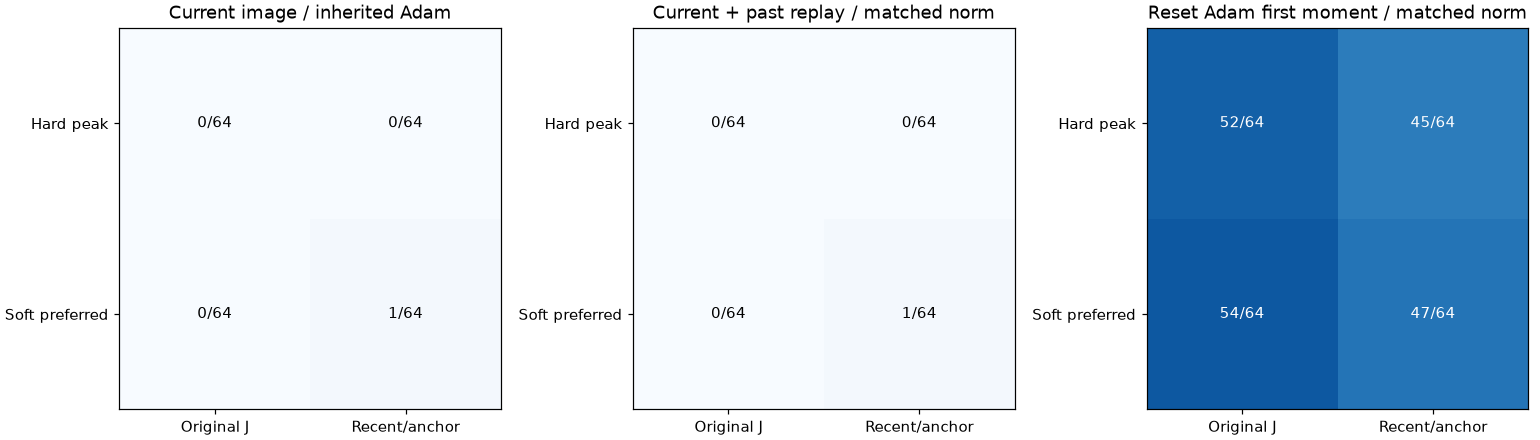



## Terminal recent-data versus anchor loss changes

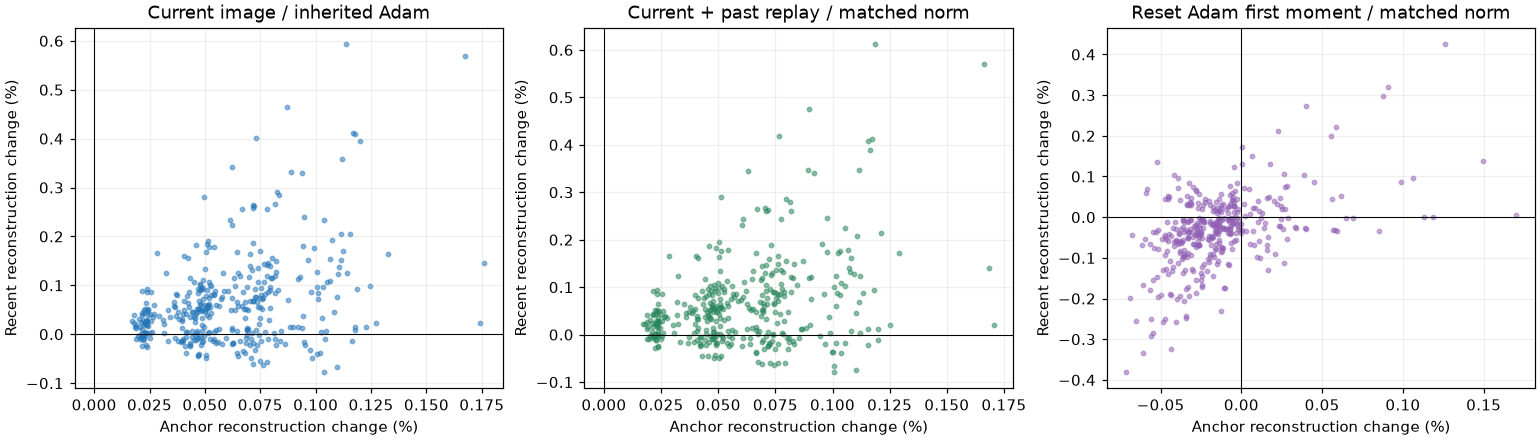

Each point is a measured sequence from the same frozen learner. Lower is better on both axes.

## Measured terminal health and the two floor rules

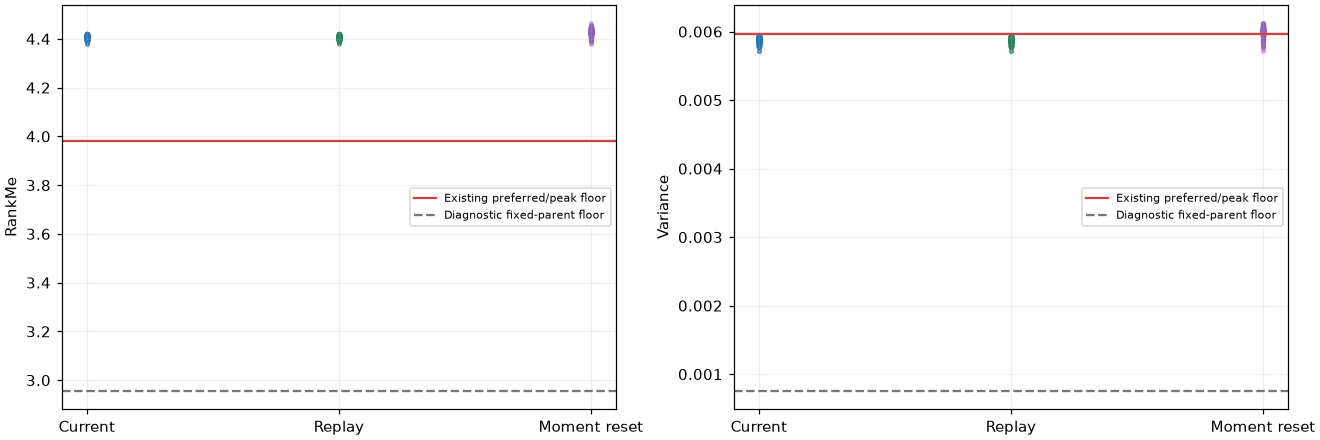

Qualification also requires first-step health. The fixed-parent floor is not a validated collapse boundary.

## Direction diagnostics at matched parameter displacement

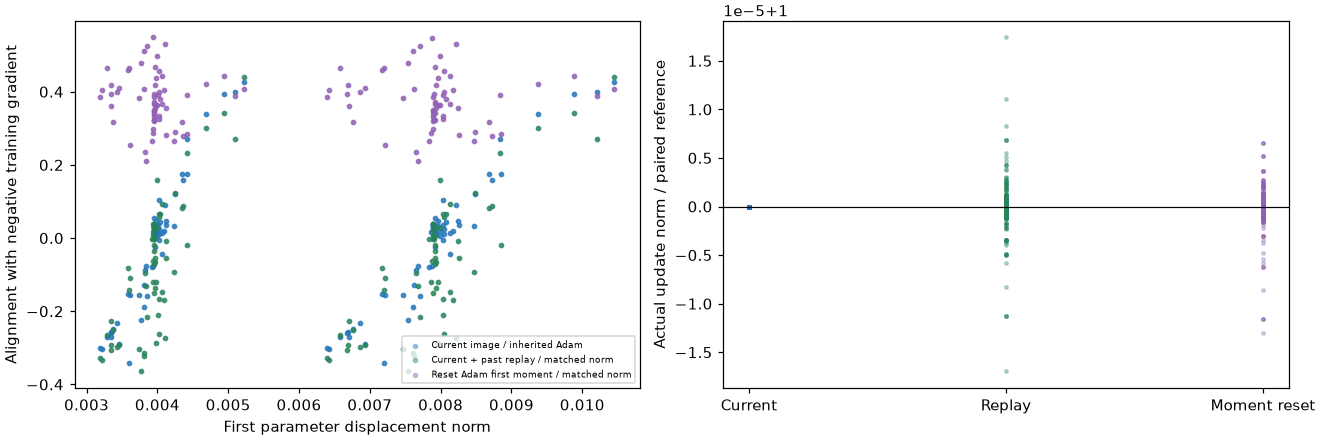



## Per-dimension health and charged branch time

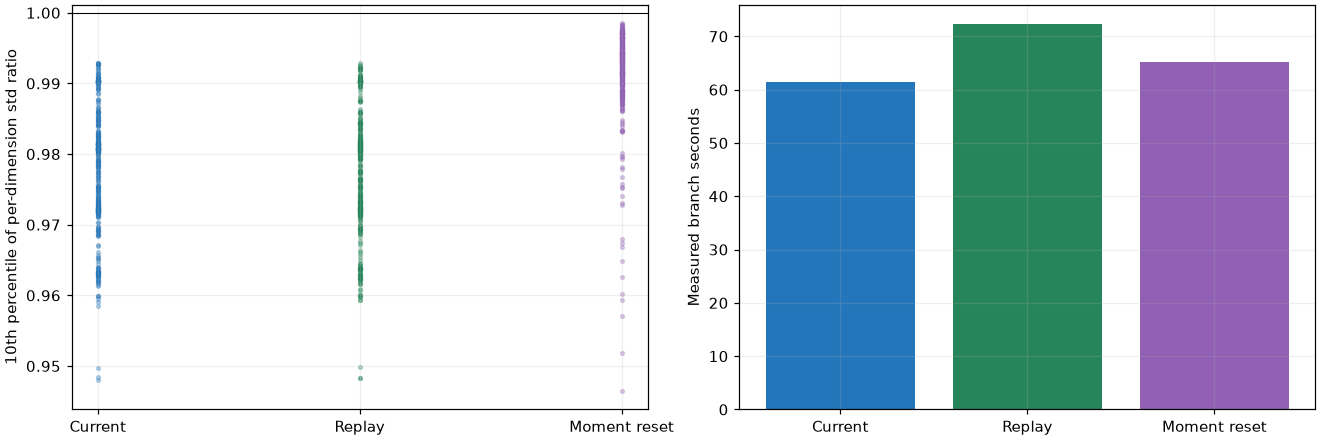

